In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("../data/dormmatch_raw.csv")

In [5]:
df.head()

,student_id,age,gender,year_of_study,branch,cgpa,sleep_time,wake_time,sleep_duration,cleanliness_level,...,guest_frequency,music_frequency,weekend_activity,food_habit,smoking_preference,ac_preference,preferred_room_type,budget,preferred_environment,roommate_interaction
0,STU0760,19,Female,3,Biotechnology,9.03,2.35,6.71,4.07,3.0,...,Often,Rarely,NaN,Vegetarian,No smoking,Yes,Double,6500.0,Balanced,2
1,STU1501,21,Male,1,EE,7.92,23.50,6.98,7.31,4.0,...,sometimes,Rarely,Gaming,Vegetarian,No smoking,Yes,Triple,6500.0,Balanced,4
2,STU1385,20,Female,4,CS,8.93,22.99,7.18,8.47,5.0,...,Sometimes,Sometimes,Movies,non-vegetarian,No smoking,No,Double,6500.0,Social,2
3,STU0052,20,Male,2,computer science,7.45,22.25,5.81,7.90,4.0,...,Often,Often,Movies,Eggetarian,No smoking,Yes,Single,5500.0,quiet,4
4,STU0660,20,Female,2,Electrical,7.02,0.77,10.68,10.38,2.0,...,Sometimes,Often,Relaxing,Non-vegetarian,No preference,Yes,Double,6000.0,Balanced,3


In [6]:
df.tail()       # Last 5 rows
df.sample(5)    # 5 randomly selected rows

,student_id,age,gender,year_of_study,branch,cgpa,sleep_time,wake_time,sleep_duration,cleanliness_level,...,guest_frequency,music_frequency,weekend_activity,food_habit,smoking_preference,ac_preference,preferred_room_type,budget,preferred_environment,roommate_interaction
161,STU1712,18,Male,1,CSE,9.30,2.12,9.41,7.63,3.0,...,Rarely,Often,Relaxing,Vegetarian,No smoking,No,Double,8000.0,Quiet,3
129,STU1152,20,Female,4,CS,7.73,NaN,7.15,8.14,5.0,...,Sometimes,Rarely,Sports,Non-vegetarian,No smoking,No preference,Double,10000.0,Balanced,1
685,STU1534,21,Female,4,cse,7.28,22.60,8.39,10.60,2.0,...,Sometimes,Never,Sports,Non-vegetarian,No preference,Yes,Double,5500.0,quiet,2
232,STU0139,19,Female,2,Computer Science,9.78,23.28,7.64,9.74,4.0,...,Rarely,Never,Study,Non-vegetarian,No smoking,Yes,Double,8000.0,Balanced,3
1289,STU1767,20,Female,3,Electrical,8.22,23.14,7.43,8.22,4.0,...,Sometimes,Never,Outings,vegetarian,Prefer smoke-free,No,Triple,5000.0,Quiet,4


In [7]:
df.shape

(2034, 25)

In [8]:
df.columns

Index(['student_id', 'age', 'gender', 'year_of_study', 'branch', 'cgpa',
       'sleep_time', 'wake_time', 'sleep_duration', 'cleanliness_level',
       'noise_tolerance', 'study_hours', 'social_activity',
       'introvert_extrovert', 'sharing_preference', 'guest_frequency',
       'music_frequency', 'weekend_activity', 'food_habit',
       'smoking_preference', 'ac_preference', 'preferred_room_type', 'budget',
       'preferred_environment', 'roommate_interaction'],
      dtype='object')

In [9]:
for col in df.columns:
    print(col)

student_id
age
gender
year_of_study
branch
cgpa
sleep_time
wake_time
sleep_duration
cleanliness_level
noise_tolerance
study_hours
social_activity
introvert_extrovert
sharing_preference
guest_frequency
music_frequency
weekend_activity
food_habit
smoking_preference
ac_preference
preferred_room_type
budget
preferred_environment
roommate_interaction


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2034 entries, 0 to 2033
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             2034 non-null   object 
 1   age                    2034 non-null   int64  
 2   gender                 2034 non-null   object 
 3   year_of_study          2034 non-null   int64  
 4   branch                 1996 non-null   object 
 5   cgpa                   1986 non-null   float64
 6   sleep_time             1949 non-null   float64
 7   wake_time              1949 non-null   float64
 8   sleep_duration         1972 non-null   float64
 9   cleanliness_level      1975 non-null   object 
 10  noise_tolerance        1987 non-null   object 
 11  study_hours            1929 non-null   object 
 12  social_activity        2034 non-null   object 
 13  introvert_extrovert    2034 non-null   int64  
 14  sharing_preference     2034 non-null   int64  
 15  gues

In [11]:
df.describe(include="object")

,student_id,gender,branch,cleanliness_level,noise_tolerance,study_hours,social_activity,guest_frequency,music_frequency,weekend_activity,food_habit,smoking_preference,ac_preference,preferred_room_type,preferred_environment
count,2034,2034,1996,1975,1987,1929,2034,2034,2034,1982,2034,2034,2034,2034,1999
unique,2000,2,24,10,10,604,10,6,4,12,8,3,3,3,6
top,STU0118,Male,computer science,4.0,2.0,3.63,3,Sometimes,Sometimes,Outings,Non-vegetarian,No smoking,Yes,Double,Balanced
freq,2,1035,176,697,469,12,539,859,813,320,862,1188,905,1186,828


In [12]:
df.isnull().sum()

student_id                 0
age                        0
gender                     0
year_of_study              0
branch                    38
cgpa                      48
sleep_time                85
wake_time                 85
sleep_duration            62
cleanliness_level         59
noise_tolerance           47
study_hours              105
social_activity            0
introvert_extrovert        0
sharing_preference         0
guest_frequency            0
music_frequency            0
weekend_activity          52
food_habit                 0
smoking_preference         0
ac_preference              0
preferred_room_type        0
budget                    85
preferred_environment     35
roommate_interaction       0
dtype: int64

In [13]:
missing = df.isnull().sum()

missing[missing > 0]

branch                    38
cgpa                      48
sleep_time                85
wake_time                 85
sleep_duration            62
cleanliness_level         59
noise_tolerance           47
study_hours              105
weekend_activity          52
budget                    85
preferred_environment     35
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(22)

In [15]:
duplicates = df[df.duplicated(keep=False)]

duplicates.head(10)

,student_id,age,gender,year_of_study,branch,cgpa,sleep_time,wake_time,sleep_duration,cleanliness_level,...,guest_frequency,music_frequency,weekend_activity,food_habit,smoking_preference,ac_preference,preferred_room_type,budget,preferred_environment,roommate_interaction
3,STU0052,20,Male,2,computer science,7.45,22.25,5.81,7.90,4.0,...,Often,Often,Movies,Eggetarian,No smoking,Yes,Single,5500.0,quiet,4
87,STU0713,20,Female,3,mechanical,8.65,23.57,6.58,6.99,5.0,...,Sometimes,Rarely,Gaming,Non-vegetarian,Prefer smoke-free,No,Double,7500.0,Social,3
194,STU0332,20,Female,2,Computer Science,5.95,23.06,5.93,6.64,4.0,...,Often,Rarely,Outings,Vegetarian,Prefer smoke-free,No preference,Triple,5000.0,Balanced,4
230,STU1477,19,Male,3,civil,8.84,2.85,9.67,8.11,5.0,...,Rarely,Never,Sports,Vegetarian,No smoking,No preference,Double,10000.0,Balanced,3
231,STU0377,21,Female,2,ECE,8.17,23.13,6.49,8.63,3.0,...,Sometimes,Rarely,Sports,Vegetarian,Prefer smoke-free,Yes,Double,8500.0,Balanced,4
246,STU1707,21,Male,2,Biotechnology,8.14,22.64,6.32,7.77,3.0,...,Sometimes,Sometimes,Movies,Vegetarian,Prefer smoke-free,Yes,Triple,5500.0,Balanced,3
312,STU0915,20,Male,1,computer science,8.28,23.32,6.88,7.37,5.0,...,Sometimes,Often,Study,eggetarian,No smoking,No,Double,6500.0,Balanced,3
369,STU0565,20,Female,2,Mechanical,6.44,1.62,8.75,6.75,NaN,...,Rarely,Often,Movies,Non-vegetarian,No smoking,No,Single,8500.0,Social,3
382,STU0007,20,Male,2,CE,8.38,0.78,NaN,7.07,5.0,...,Sometimes,Sometimes,Outings,Vegetarian,No smoking,Yes,Single,8000.0,Quiet,4
400,STU0377,21,Female,2,ECE,8.17,23.13,6.49,8.63,3.0,...,Sometimes,Rarely,Sports,Vegetarian,Prefer smoke-free,Yes,Double,8500.0,Balanced,4


In [16]:
df["branch"].value_counts(dropna=False)

branch
computer science          176
cse                       160
 CS                       156
CSE                       155
Computer Science          143
it                        117
IT                         88
Electronics                87
Information Technology     84
 ME                        75
ece                        70
biotech                    69
ECE                        64
mechanical                 59
civil                      59
Biotechnology              59
Mechanical                 57
CE                         56
 ECE                       55
 BT                        47
EE                         45
Electrical                 40
NaN                        38
Civil                      38
electrical                 37
Name: count, dtype: int64

In [17]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{'='*40}")
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False).head(15))


Column: student_id
student_id
STU0118    2
STU0829    2
STU1558    2
STU1707    2
STU1647    2
STU1926    2
STU0918    2
STU0355    2
STU1125    2
STU0602    2
STU1472    2
STU0915    2
STU1252    2
STU0377    2
STU1477    2
Name: count, dtype: int64

Column: gender
gender
Male      1035
Female     999
Name: count, dtype: int64

Column: branch
branch
computer science          176
cse                       160
 CS                       156
CSE                       155
Computer Science          143
it                        117
IT                         88
Electronics                87
Information Technology     84
 ME                        75
ece                        70
biotech                    69
ECE                        64
mechanical                 59
civil                      59
Name: count, dtype: int64

Column: cleanliness_level
cleanliness_level
4.0      697
5.0      555
3.0      467
2.0      160
1.0       63
NaN       59
3.0/5     13
5.0/5     11
4.0/5      7
1.0/5   

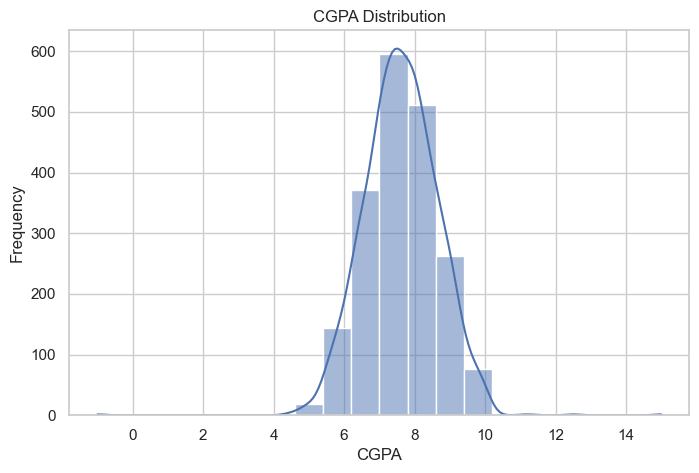

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(df["cgpa"], bins=20, kde=True)

plt.title("CGPA Distribution")
plt.xlabel("CGPA")
plt.ylabel("Frequency")

plt.show()